In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
print("Libraries imported successfully")

Libraries imported successfully


In [5]:
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
print("Dataset loaded",file_name)
display(df.head())


Saving students (1).csv to students (1) (1).csv
Dataset loaded students (1) (1).csv


,Study_Hours,Attendance,Marks,Result
0,1.0,52,28,Fail
1,1.5,58,32,Fail
2,2.0,60,38,Pass
3,2.5,65,42,Pass
4,3.0,68,45,Pass


In [6]:
x=df[['Study_Hours','Attendance','Marks']]
y=df['Result']
print("Input features:")
display(x.head())
print("Target variable:")
display(y.head())

Input features:


,Study_Hours,Attendance,Marks
0,1.0,52,28
1,1.5,58,32
2,2.0,60,38
3,2.5,65,42
4,3.0,68,45


Target variable:


,Result
0,Fail
1,Fail
2,Pass
3,Pass
4,Pass


In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)
print("Training records:", len(X_tr))
print("Testing records:", len(X_te))

Training records: 24
Testing records: 6


In [10]:
tree_clf = DecisionTreeClassifier(max_depth=4,random_state=42)
tree_clf.fit(X_tr, y_tr)
print("Decision Tree model trained successfully");

Decision Tree model trained successfully


In [11]:
y_pred=tree_clf.predict(X_te)
comaprison=pd.DataFrame({
    'Actual':y_te.values,
    'Predicted Result':y_pred
})
display(comaprison.head)

<bound method NDFrame.head of   Actual Predicted Result
0   Pass             Pass
1   Pass             Pass
2   Pass             Pass
3   Pass             Pass
4   Pass             Pass
5   Pass             Fail>

In [13]:
print("Accuracy:",round(accuracy_score(y_te,y_pred),3))
print("\nClassification Report:")
print(classification_report(y_te,y_pred,zero_division=0))

Accuracy: 0.833

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         0
        Pass       1.00      0.83      0.91         6

    accuracy                           0.83         6
   macro avg       0.50      0.42      0.45         6
weighted avg       1.00      0.83      0.91         6



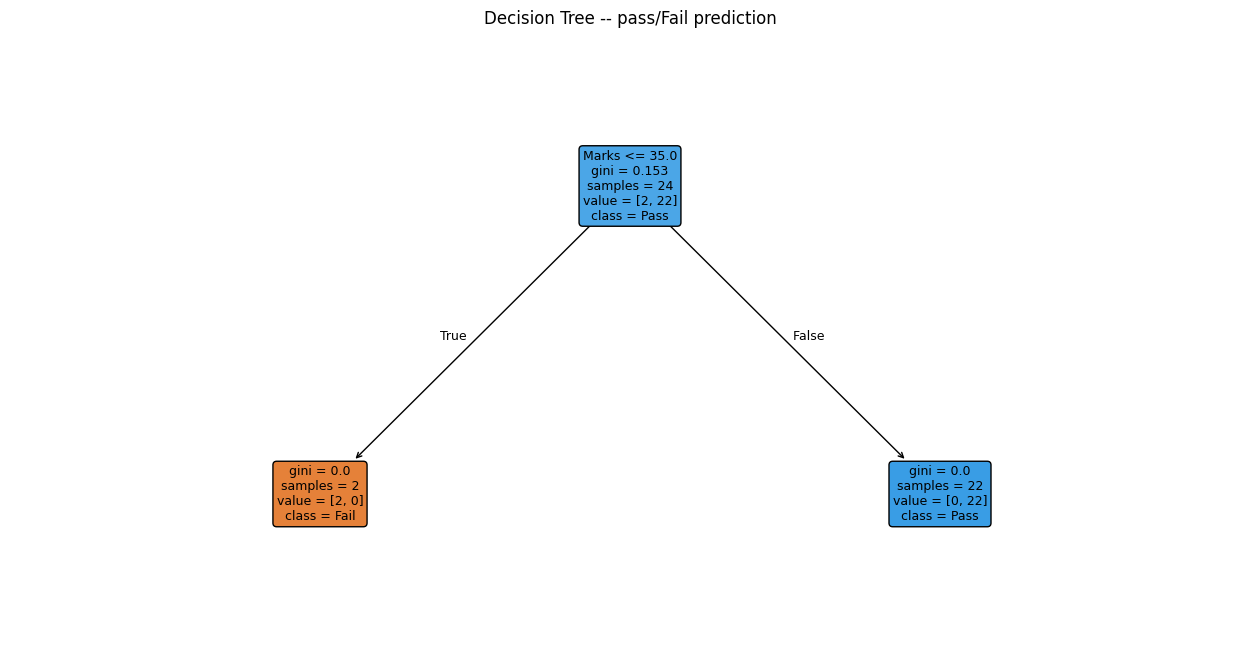

In [16]:
plt.figure(figsize=(16,8))
plot_tree(tree_clf,feature_names=x.columns,class_names=[str(c) for c in tree_clf.classes_],filled=True,rounded=True,fontsize=9)
plt.title("Decision Tree -- pass/Fail prediction")
plt.show()